# PA3 — Poucos rótulos (fauna em câmeras trap) · Trilha B (FixMatch)

Notebook de execução completa, na ordem: setup → dados → testes → escolha de hiperparâmetros no val → Parte 0 → Partes 1 e 2 → diagnósticos → ablação → modelo entregue e Parte 3 → verificação do `predict.py`.

- Os hiperparâmetros usados nos resultados estão em `configs/selected/`, gerados pelos sweeps (seção 3 e 5); nenhum valor de treino é fixo no código.
- O `test_public` não participa de nenhuma seleção: cada run o avalia uma única vez, no checkpoint escolhido pelo val.
- Todas as etapas são retomáveis: sweeps e runs já concluídos são pulados. Após um reinício da sessão, executar a célula de setup (seção 0) e a de dados (seção 1) e prosseguir.
- Ambiente: GPU (T4 ou superior).

## 0. Setup e constantes

In [2]:
# Origem do código: URL de um repositório git ou, se vazia, o arquivo ZIP do projeto em /content.
REPO_URL = ""
ZIP_NAME = "pa3-poucos-rotulos.zip"
USE_DRIVE = True         # resultados/, configs/selected/ e pesos/ ficam no Drive e sobrevivem a quedas da sessão
DRIVE_DIR = "/content/drive/MyDrive/pa3"

import os, subprocess
os.chdir("/content")
if not os.path.isdir("/content/pa3-poucos-rotulos"):
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, "pa3-poucos-rotulos"], check=True)
    else:
        subprocess.run(["unzip", "-q", f"/content/{ZIP_NAME}", "-d", "/content"], check=True)
os.chdir("/content/pa3-poucos-rotulos")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    import shutil
    for d in ["resultados", "configs/selected", "pesos"]:
        tgt = f"{DRIVE_DIR}/{d}"
        os.makedirs(tgt, exist_ok=True)
        if os.path.islink(d):
            continue
        if os.path.isdir(d):
            for f in os.listdir(d):
                if not os.path.exists(f"{tgt}/{f}"):
                    shutil.move(f"{d}/{f}", f"{tgt}/{f}")
            shutil.rmtree(d)
        os.symlink(tgt, d)
    # pastas das variantes de ablação (seção 7): também persistem no Drive
    for d in ["resultados_sem_correcao", "resultados_sem_correcao_tau05", "resultados_3000passos"]:
        tgt = f"{DRIVE_DIR}/{d}"
        os.makedirs(tgt, exist_ok=True)
        if not os.path.islink(d):
            if os.path.isdir(d):
                shutil.rmtree(d)
            os.symlink(tgt, d)
print("pasta de trabalho:", os.getcwd())

# Constantes usadas pelas células seguintes.
import json, sys, glob
from IPython.display import Image, display
DADOS = "/content/dados"        # pacote do enunciado descompactado
CACHE = "/content/cache"        # arrays pré-redimensionados em disco local (acelera reinícios)
SEEDS_SWEEP = "0 1"             # seeds de cada trial dos sweeps
N_SCRATCH, N_FT, N_FM = 12, 20, 8   # trials por sweep: CNN do zero, backbone ImageNet, FixMatch
FM_STEPS_SWEEP = 1500           # passos de cada trial do FixMatch (o run final herda este valor)
FM_BS = 16                      # lote rotulado do FixMatch; cada passo processa FM_BS·(1+2·mu) imagens
MAX_MIN = 120                   # um sweep deixa de iniciar trials após este tempo (retomável)
EXTRA_3000 = True               # análise extra da seção 7.4 (FixMatch com 3000 passos)

Mounted at /content/drive
pasta de trabalho: /content/pa3-poucos-rotulos


In [3]:
!pip -q install -r requirements.txt

In [4]:
!nvidia-smi | head -15
!python -c "import torch;print(torch.__version__, 'cuda:', torch.cuda.is_available())"

Wed Nov 18 02:23:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Dados
Pacote do enunciado (id do Drive em `configs/project.json`). Se o download via gdown falhar por cota, o arquivo `/content/pa3_dados.zip` pode ser colocado manualmente; a célula só descompacta quando o arquivo já existe.

In [5]:
FILE_ID = json.load(open("configs/project.json"))["pacote_drive_id"]
if not os.path.exists("/content/pa3_dados.zip"):
    !gdown --id {FILE_ID} -O /content/pa3_dados.zip
!mkdir -p /content/dados && unzip -q -n /content/pa3_dados.zip -d /content/dados
!ls /content/dados | head

pa3_dados


## 2. Testes de código e de dados

In [ ]:
!python -m tests.test_units

`check_data` confere o pacote contra o enunciado (contagens, orçamentos aninhados, splits disjuntos) e detecta o schema dos CSVs, gravando `configs/data_schema.json`. A saída inclui os cabeçalhos dos CSVs, o schema detectado e estatísticas de proporção e cor das imagens. Quando uma coluna não é reconhecida, `--image_col` e `--label_col` as fixam.

In [6]:
!python -m tests.check_data --data {DADOS}


===== check_data =====
[PASS] arquivo classes.csv — /content/dados/pa3_dados/classes.csv
[PASS] arquivo rotulos_1.csv — /content/dados/pa3_dados/labels/rotulos_1.csv
[PASS] arquivo rotulos_5.csv — /content/dados/pa3_dados/labels/rotulos_5.csv
[PASS] arquivo rotulos_20.csv — /content/dados/pa3_dados/labels/rotulos_20.csv
[PASS] arquivo val.csv — /content/dados/pa3_dados/labels/val.csv
[PASS] arquivo test_public.csv — /content/dados/pa3_dados/labels/test_public.csv
[PASS] pool não rotulado: pasta 'train' com imagens (não há train.csv) — /content/dados/pa3_dados/images/train

--- cabeçalhos (confira se o schema detectado faz sentido) ---
classes.csv: 21 linhas | colunas ['idx', 'label']
 idx               label
   0 american_black_bear
   1       american_crow
rotulos_1.csv: 21 linhas | colunas ['image_id', 'label']
        image_id               label
64e6f65bcf6e4dcf american_black_bear
42cf41f2234919f5       american_crow
rotulos_5.csv: 105 linhas | colunas ['image_id', 'label']
     

Visualização das aumentações (o animal chega a ocupar menos de 2% do quadro; a figura mostra se ele sobrevive ao recorte, o que motiva `aug.scale_min` e `weak_scale_min` nos sweeps).

In [ ]:
!python -m tests.viz_aug --data {DADOS} --out resultados/diagnosticos/aug.png
display(Image("resultados/diagnosticos/aug.png"))

`check_pipeline` (com os valores iniciais, só para testar o código): limite de parâmetros, download dos pesos ImageNet, overfit sem aumentação, reprodutibilidade por seed, guarda contra uso do `test_public` na seleção, FixMatch nas quatro correções de desbalanceamento e tempo por passo. O tempo medido orienta `FM_STEPS_SWEEP` e `N_FM`.

In [ ]:
!python -m tests.check_pipeline --data {DADOS} --cache {CACHE} --fm_steps 40

## 3. Escolha de hiperparâmetros (somente no val)
Busca aleatória sobre os espaços de `configs/sweeps/*.json`; o trial 0 usa os valores iniciais. O resumo mostra média ± desvio entre seeds (o val tem 202 imagens, então diferenças menores que o desvio são ruído) e compara com o trial 0. O melhor trial é gravado em `configs/selected/`.

In [ ]:
print(dict(DADOS=DADOS, CACHE=CACHE, SEEDS_SWEEP=SEEDS_SWEEP, N_SCRATCH=N_SCRATCH, N_FT=N_FT, N_FM=N_FM,
           FM_STEPS_SWEEP=FM_STEPS_SWEEP, FM_BS=FM_BS, MAX_MIN=MAX_MIN))
assert os.path.isdir(DADOS), "pacote de dados ausente: executar a célula da seção 1"

CNN treinada do zero (Parte 0a), orçamento 5.

In [ ]:
!python -m src.sweep --data {DADOS} --method part0_scratch --budget 5 --seeds {SEEDS_SWEEP} --n_trials {N_SCRATCH} --out resultados/sweeps --cache {CACHE} --max_minutes {MAX_MIN}

Backbone ImageNet (Parte 0b), orçamento 5. Este sweep também escolhe a arquitetura, o tamanho de entrada e o modo de redimensionamento; o FixMatch herda essa escolha.

In [12]:
!python -m src.sweep --data {DADOS} --method part0_ft --budget 5 --seeds {SEEDS_SWEEP} --n_trials {N_FT} --out resultados/sweeps --cache {CACHE} --max_minutes {MAX_MIN}

part0_ft b5: 20 trials × seeds [0, 1] | config-base: DEFAULTS (não validados)

--- trial 6 [74f0519278] seed 0: {'model.arch': 'efficientnet_b0', 'data.size': 320, 'data.resize_mode': 'squash', 'train.lr': 0.000801, 'train.wd': 0.0305, 'train.epochs': 40, 'aug.scale_min': 0.15}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 128MB/s]
    val F1 0.429 | val loss 2.621 | 2.4 min

--- trial 6 [74f0519278] seed 1: {'model.arch': 'efficientnet_b0', 'data.size': 320, 'data.resize_mode': 'squash', 'train.lr': 0.000801, 'train.wd': 0.0305, 'train.epochs': 40, 'aug.scale_min': 0.15}
    val F1 0.445 | val loss 2.356 | 2.4 min

--- trial 7 [e6b1d48502] seed 0: {'model.arch': 'efficientnet_b0', 'data.size': 320, 'data.resize_mode': 'squash', 'train.lr': 0.000192, 'train.wd': 0.00504, 'train.epochs': 20, 'aug.scale_min': 0.15}
    val F1 0.286 | val 

Piso nos orçamentos 1 e 20: backbone travado no do orçamento 5; variam apenas lr, wd, épocas e aumentação.

In [ ]:
for b in (1, 20):
    !python -m src.sweep --data {DADOS} --method part0_ft --budget {b} --seeds 0 --n_trials {N_SCRATCH} --out resultados/sweeps --cache {CACHE}

backbone/data travados em /content/pa3-poucos-rotulos/configs/selected/part0_ft_b5.json
part0_ft b1: 12 trials × seeds [0] | config-base: DEFAULTS (não validados)

--- trial 0 [9fbaf32662] seed 0: defaults
    val F1 0.210 | val loss 2.802 | 1.3 min

--- trial 1 [e31750c0e1] seed 0: {'train.lr': 0.00177, 'train.wd': 0.0188, 'train.epochs': 40, 'aug.scale_min': 0.15}
    val F1 0.234 | val loss 4.085 | 1.2 min

--- trial 2 [4eab8e7df9] seed 0: {'train.lr': 0.000241, 'train.wd': 0.00342, 'train.epochs': 40, 'aug.scale_min': 0.4}
    val F1 0.206 | val loss 2.786 | 1.2 min

--- trial 3 [697a3e1316] seed 0: {'train.lr': 0.00269, 'train.wd': 0.00119, 'train.epochs': 20, 'aug.scale_min': 0.7}
    val F1 0.266 | val loss 2.680 | 0.6 min

--- trial 4 [003d956625] seed 0: {'train.lr': 0.000161, 'train.wd': 0.000263, 'train.epochs': 20, 'aug.scale_min': 0.7}
    val F1 0.127 | val loss 2.945 | 0.6 min

--- trial 5 [c9280d82b6] seed 0: {'train.lr': 0.00152, 'train.wd': 0.0916, 'train.epochs': 80,

## 4. Parte 0 — piso (CNN do zero e backbone ImageNet; `test_public` avaliado uma vez, no checkpoint escolhido pelo val)

In [ ]:
!python -m src.part0 --data {DADOS} --out resultados --method both --budget 5 --seed 0 --cache {CACHE}
for m in ("part0_scratch", "part0_ft"):
    r = json.load(open(f"resultados/runs/{m}_b5_s0/metrics.json"))
    print(f"{m:14s} test F1 macro {r['test_f1']:.3f} | acurácia {r['test_acc']:.3f} | parâmetros {r['params']:,} | "
          f"época escolhida {r['best_epoch']} | 1ª época com 100% no treino: {r['epoch_train_acc_100']} | mín. val loss: época {r['epoch_min_val_loss']}")
display(Image("resultados/runs/part0_ft_b5_s0/curva.png"))
display(Image("resultados/runs/part0_ft_b5_s0/confusao.png"))

## 5. Parte 1, Trilha B — FixMatch: escolha de τ e da correção de desbalanceamento (no val)

Verificação de memória da GPU. O backbone e o tamanho escolhidos no sweep do piso podem ser bem mais pesados que os iniciais, e cada passo do FixMatch processa `FM_BS·(1+2·mu)` imagens. `probe_memory` mede o pico com o backbone selecionado e indica o lote que cabe; `FM_BS` (seção 0) é ajustado conforme o resultado. Em caso de `CUDA out of memory`, confere-se se há outro processo na GPU (`nvidia-smi`; `pkill -f "python -m src"`).

In [ ]:
!nvidia-smi --query-gpu=memory.used,memory.total --format=csv
!python -m tests.probe_memory --data {DADOS} --cache {CACHE}

In [ ]:
!python -m src.sweep --data {DADOS} --method fixmatch --budget 5 --seeds 0 --n_trials {N_FM} --out resultados/sweeps --cache {CACHE} --set train.steps={FM_STEPS_SWEEP} train.bs={FM_BS} --max_minutes {MAX_MIN}

A seleção do sweep define τ, a correção, λ, lr e as aumentações; o número de passos e o lote do run final herdam os do sweep. A configuração selecionada:

In [ ]:
sel_fm = json.load(open("configs/selected/fixmatch_b5.json"))
print("fix:", sel_fm["fix"]); print("train:", sel_fm["train"]); print("aug:", sel_fm["aug"])
print("model/data:", sel_fm["model"], sel_fm["data"])

## 6. Parte 2 — curva de orçamento (1, 5 e 20 rótulos por classe)
Piso e FixMatch nos três orçamentos, com 3 seeds no orçamento 5. Cada run avalia o `test_public` uma única vez. Saídas: `resultados/curva_orcamento.csv`, o gráfico (eixo x em log, linha do teto 0,686) e o ganho por classe no orçamento 5. O piso é re-tunado em cada orçamento; o FixMatch reaproveita a configuração selecionada no orçamento 5, o que é conservador para o método.

In [ ]:
!python -m src.run_final --data {DADOS} --out resultados --cache {CACHE}
!python -m src.grafico_orcamento --out resultados
display(Image("resultados/parte2/grafico_orcamento.png"))
display(Image("resultados/parte2/ganho_por_classe_fixmatch.png"))

In [ ]:
import pandas as pd
cv = pd.read_csv("resultados/curva_orcamento.csv")
print(cv.groupby(["metodo", "orcamento"]).agg(f1_media=("f1_macro", "mean"), f1_desvio=("f1_macro", "std"),
                                              acuracia_media=("acuracia", "mean"), n_seeds=("seed", "nunique")).round(4))

## 7. Diagnósticos da Trilha B
### 7.1 Pseudo-rotulador por classe × τ e viés para classes grandes (run FixMatch, orçamento 5, seed 0)
`diag_tau.png`: precisão e cobertura do pseudo-rotulador por classe × τ no `test_public`, calculadas com a correção do run (diagnóstico apenas; o τ foi escolhido no val). `diag_tau_bruto.png`: o mesmo com a confiança bruta ≥ τ, sem FlexMatch nem alinhamento de distribuição. Com `fix.corr=flex`, o limiar efetivo é `max(τ·β/(2−β), flex_floor)`; quando β é pequeno ele se reduz ao piso e a curva fica plana em τ, de modo que a versão bruta é a que isola o efeito de τ. `vies_pseudorotulos.png`: fração real × fração de pseudo-rótulos por classe.

In [ ]:
run = "resultados/runs/fixmatch_b5_s0"
for f in ("diag_tau.png", "diag_tau_bruto.png", "vies_pseudorotulos.png"):
    display(Image(f"{run}/{f}"))
print(json.load(open(f"{run}/metrics.json")))

### 7.2 Calibração, τ bruto e erro em imagens cinza × coloridas (sem retreinar)
Calculados a partir dos `test_probs.npy` de cada run: ECE e diagrama de confiabilidade, precisão e cobertura por τ com a confiança bruta, e taxa de erro em imagens cinza × coloridas com a proporção base de imagens cinza.

In [ ]:
RUNS = [f"resultados/runs/{m}_b5_s{s}" for m in ("fixmatch", "part0_ft") for s in (0, 1, 2)]
RUNS = [r for r in RUNS if os.path.exists(r + "/test_probs.npy")]
!python -m src.diag_offline --data {DADOS} --runs {" ".join(RUNS)} --out resultados/diag_offline
display(Image("resultados/diag_offline/confiabilidade.png"))

### 7.3 Ablação controlada do FixMatch (orçamento 5, 3 seeds por variante)
Mesmo backbone, lr, passos e seeds; varia apenas o que consta em `--set`. A variante A é a configuração selecionada no sweep (seção 5).
- B: sem correção de desbalanceamento (`fix.corr=none`), com o τ selecionado.
- C: sem correção, com τ = 0,5. B × C isola o efeito do limiar; C × A isola o efeito da correção quando o limiar efetivo de A coincide com o piso.

In [ ]:
!python -m src.run_final --data {DADOS} --out resultados_sem_correcao --methods fixmatch --budgets 5 --cache {CACHE} --set fix.corr='"none"'

In [7]:
!python -m src.run_final --data {DADOS} --out resultados_sem_correcao_tau05 --methods fixmatch --budgets 5 --cache {CACHE} --set fix.corr='"none"' fix.tau=0.5

Plano:
  fixmatch b5 s0
  fixmatch b5 s1
  fixmatch b5 s2
[pula] fixmatch_b5_s0 (já existe)
[pula] fixmatch_b5_s1 (já existe)

=== fixmatch_b5_s2 | config: /content/pa3-poucos-rotulos/configs/selected/fixmatch_b5.json
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 125MB/s] 
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This D

                        pasta corr  tau  n      val_f1     test_f1 test_acc  mask   Δval vs 1ª  Δtest vs 1ª
                   resultados flex 0.95  3 0.424±0.019 0.488±0.014    0.536 0.988          NaN          NaN
      resultados_sem_correcao none 0.95  3 0.413±0.018 0.487±0.036    0.531 0.622 -0.011±0.008 -0.001±0.044
resultados_sem_correcao_tau05 none 0.50  3 0.419±0.022 0.487±0.014    0.535 0.989 -0.005±0.009 -0.000±0.000

Diferenças menores que o desvio entre seeds (n=3) são ruído; a escolha do modelo é pelo val.


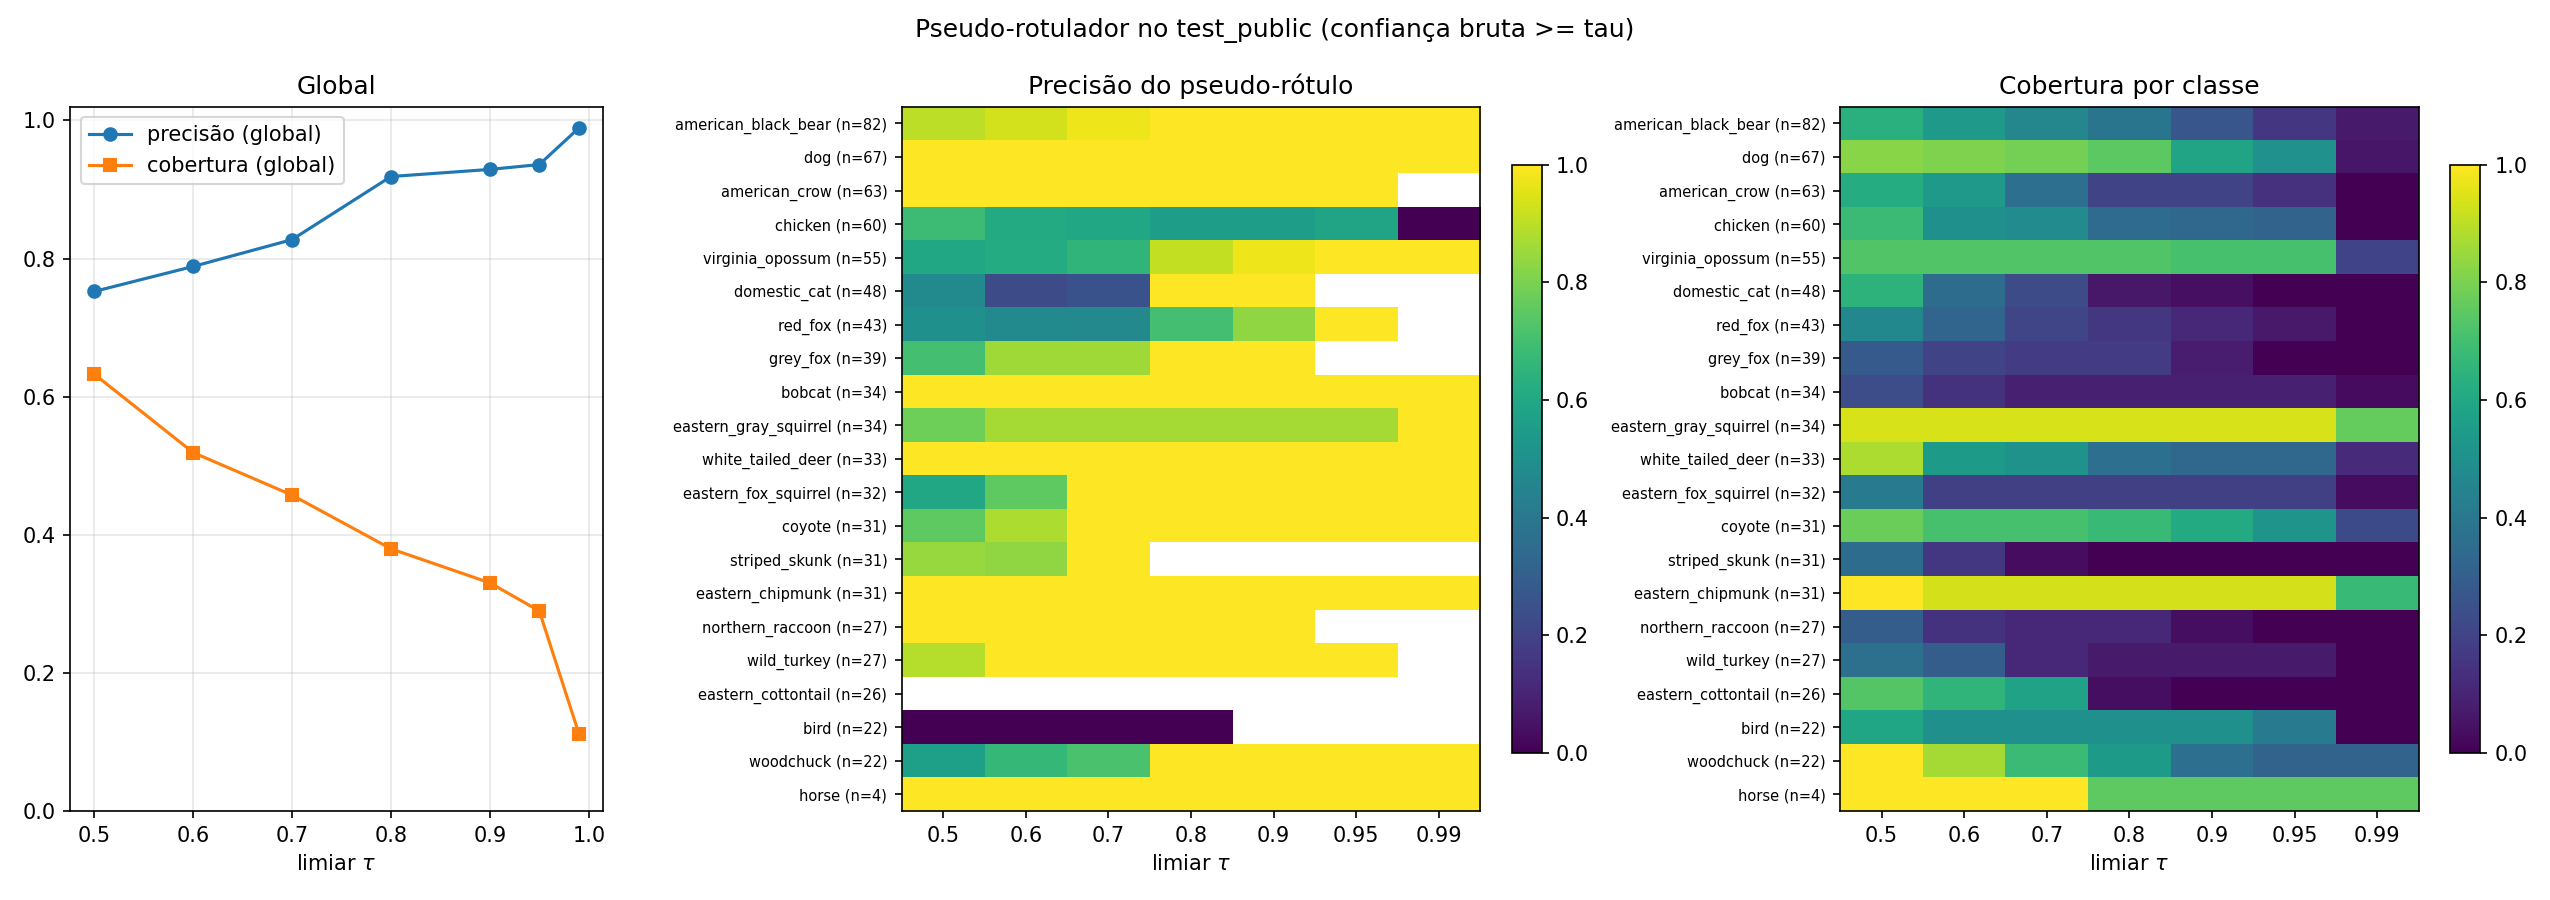

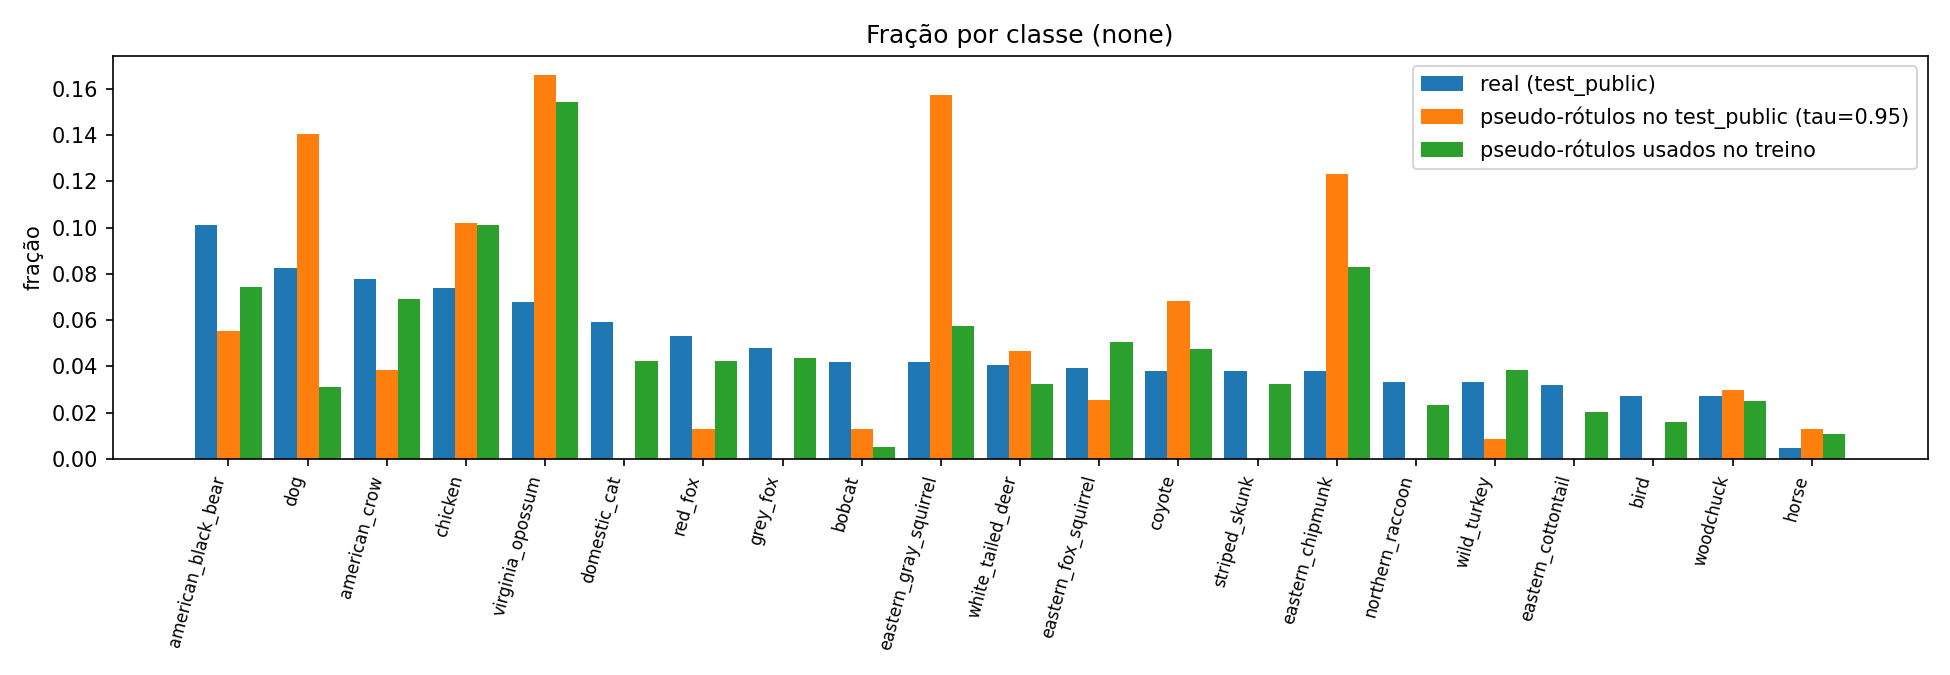

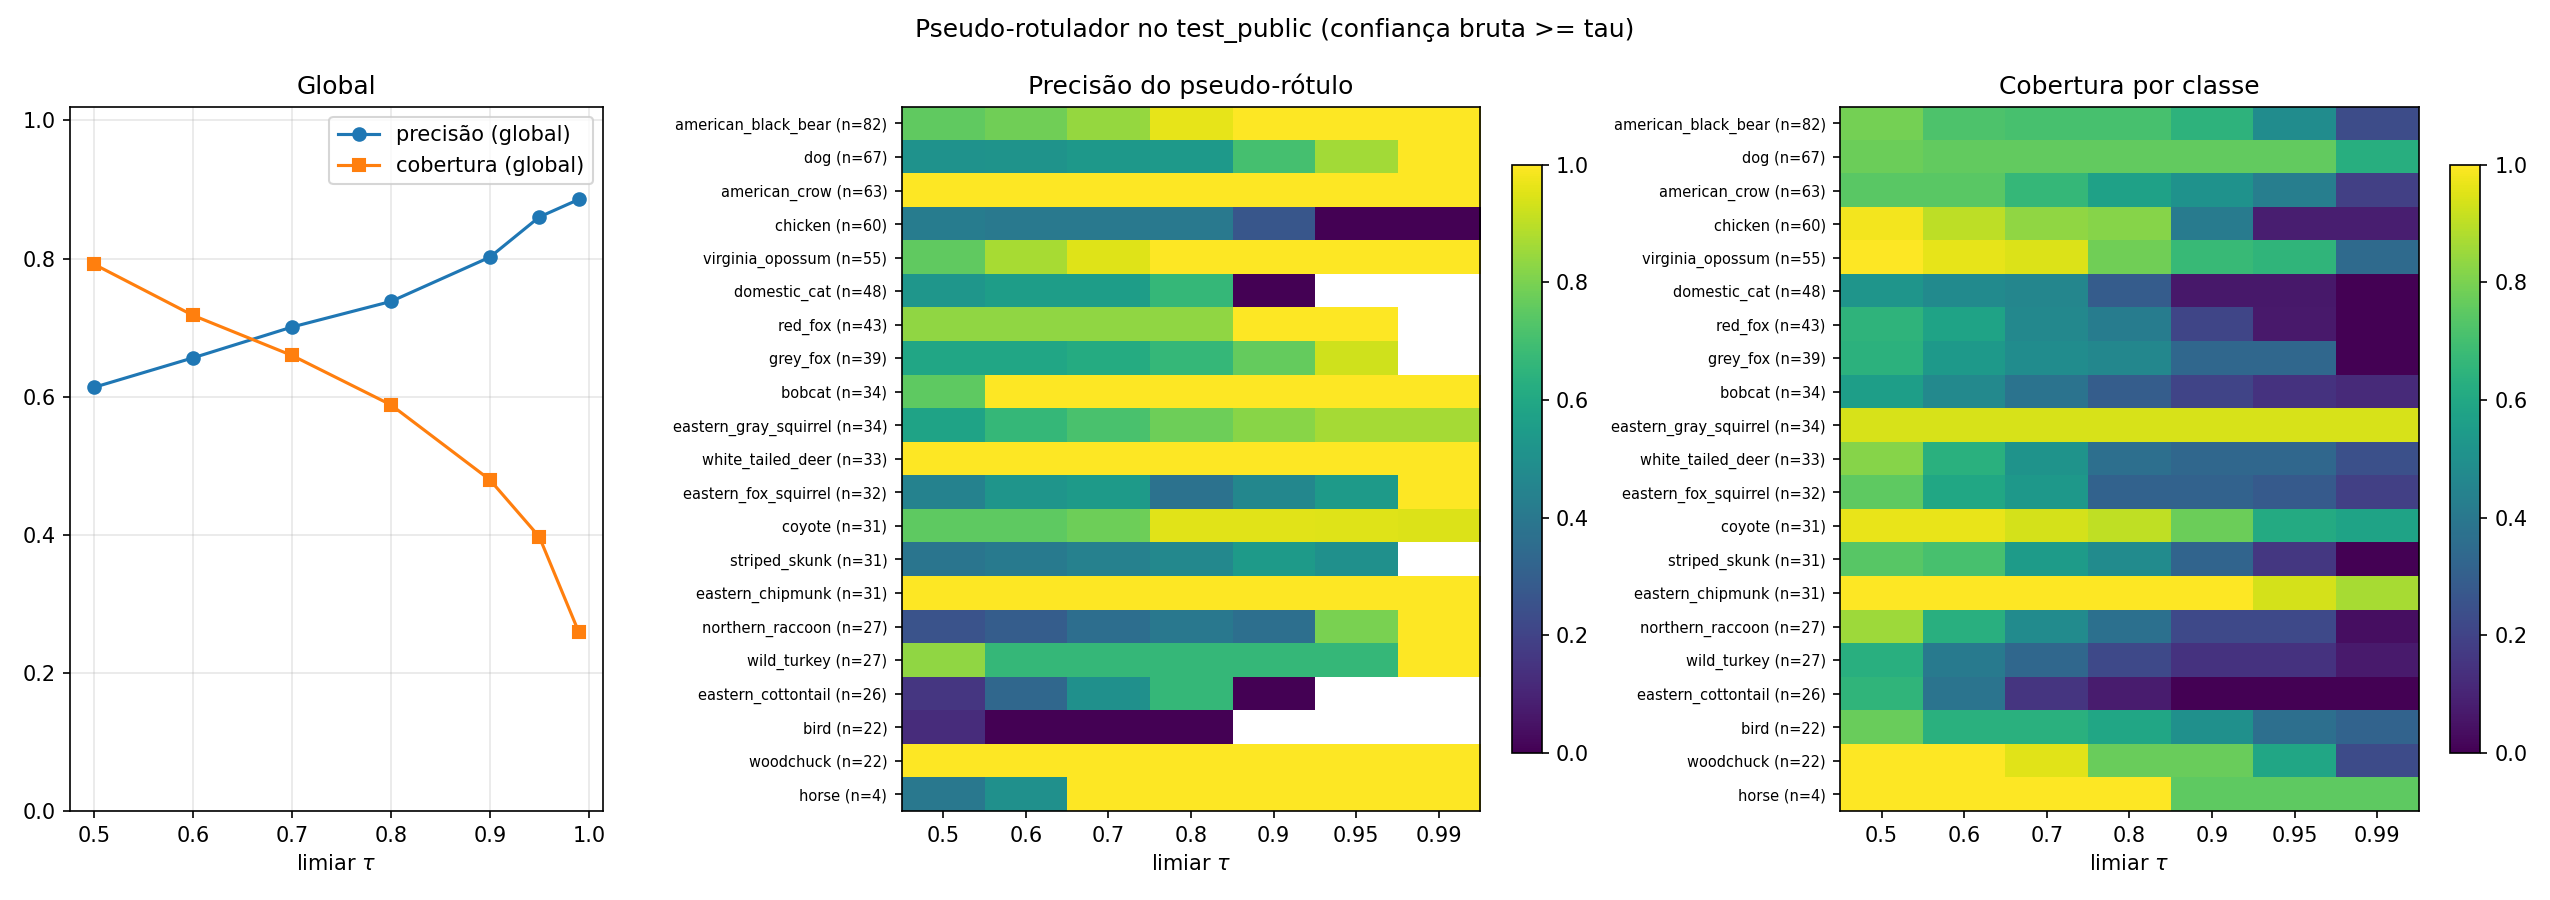

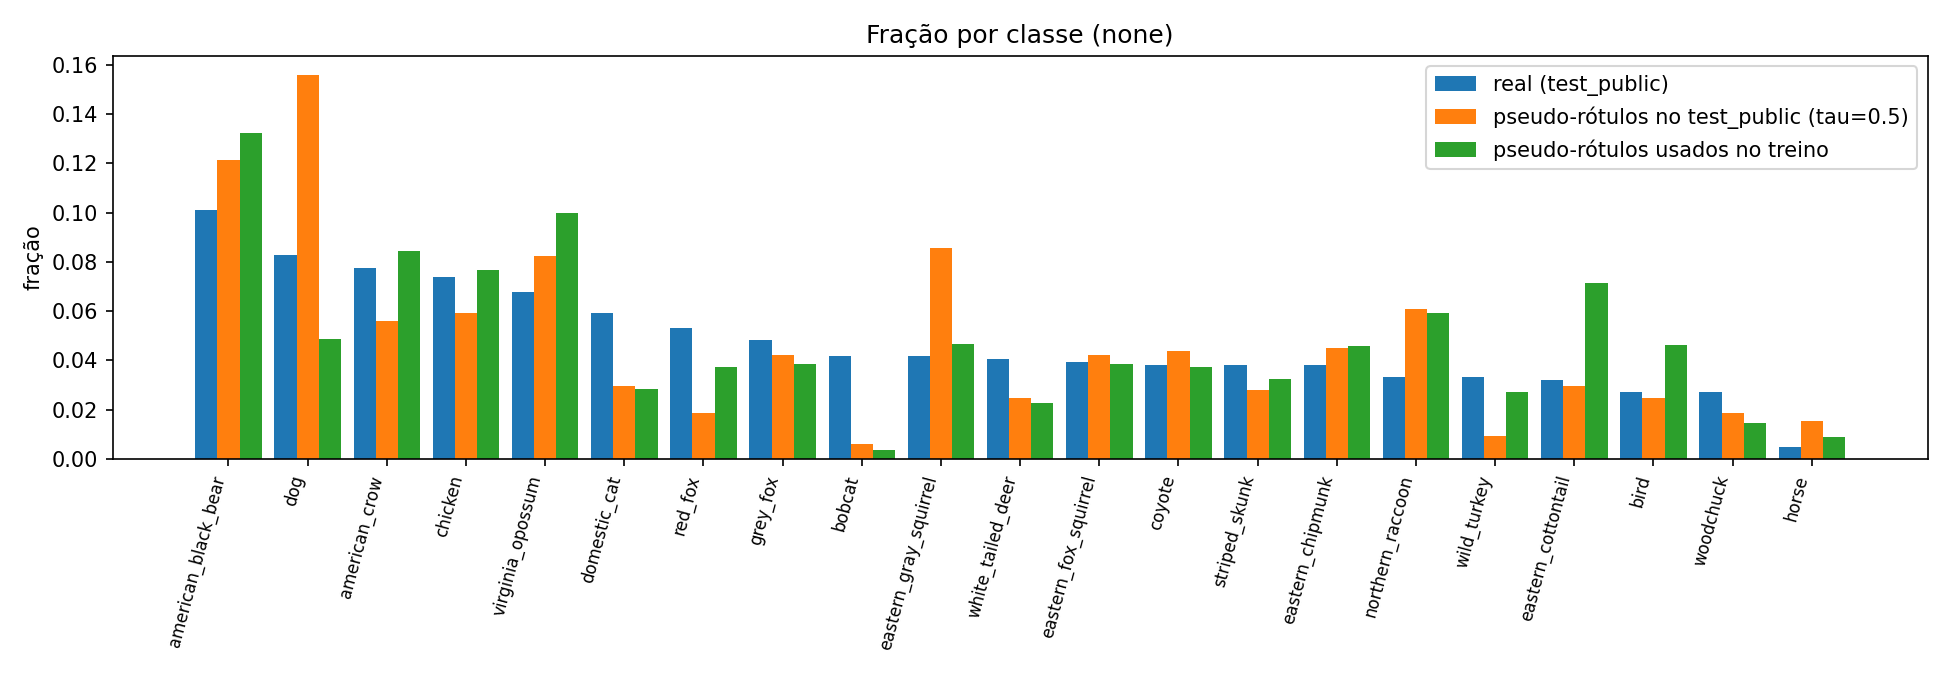

In [8]:
!python -m src.comparar_ablacao resultados resultados_sem_correcao resultados_sem_correcao_tau05
for d in ("resultados_sem_correcao", "resultados_sem_correcao_tau05"):
    for f in ("diag_tau_bruto.png", "vies_pseudorotulos.png"):
        display(Image(f"{d}/runs/fixmatch_b5_s0/{f}"))

### 7.4 Análise extra: FixMatch com 3000 passos (em vez de 1500)
O F1 do FixMatch ainda crescia ao fim do treino. Esta análise (3 seeds, orçamento 5) é reportada à parte; a configuração oficial é a do sweep. Controlada por `EXTRA_3000` (seção 0).

In [ ]:
if EXTRA_3000:
    !python -m src.run_final --data {DADOS} --out resultados_3000passos --methods fixmatch --budgets 5 --cache {CACHE} --set train.steps=3000
    !python -m src.comparar_ablacao resultados resultados_3000passos

## 8. Modelo entregue, Parte 3 e verificação do `predict.py`
O modelo entregue é escolhido apenas pelo val: dentro de cada pasta, a seed de maior val F1 (`select_final`); entre as variantes de 7.3, a de maior val F1 médio entre as 3 seeds. A variante 3000 passos (7.4) é análise extra e não entra na escolha.

In [9]:
import numpy as np
cand = {}
for d in ("resultados", "resultados_sem_correcao", "resultados_sem_correcao_tau05"):
    v = [json.load(open(f))["val_f1"] for f in sorted(glob.glob(f"{d}/runs/fixmatch_b5_s*/metrics.json"))]
    if len(v) == 3:
        cand[d] = float(np.mean(v))
print({k: round(x, 4) for k, x in cand.items()})
MODELO_OUT = max(cand, key=cand.get)
print("pasta do modelo entregue (maior val F1 médio):", MODELO_OUT)

{'resultados': 0.4244, 'resultados_sem_correcao': 0.4131, 'resultados_sem_correcao_tau05': 0.4192}
pasta do modelo entregue (maior val F1 médio): resultados


           run   val_f1  val_loss  params
fixmatch_b5_s2 0.444432  2.434592 4034449
fixmatch_b5_s1 0.421363  2.880885 4034449
fixmatch_b5_s0 0.407259  2.863844 4034449

Exportado fixmatch_b5_s2 -> pesos/modelo_final.pt (4,034,449 parâmetros)
test_public: 811 imagens | 381 erros | acc 0.530
Salvo em resultados/parte3/: galeria_erros.png, galeria_acertos.png, galeria_info.csv, candidatos_erros.csv
Preencham a coluna 'diagnostico' em galeria_info.csv (texto é de vocês).


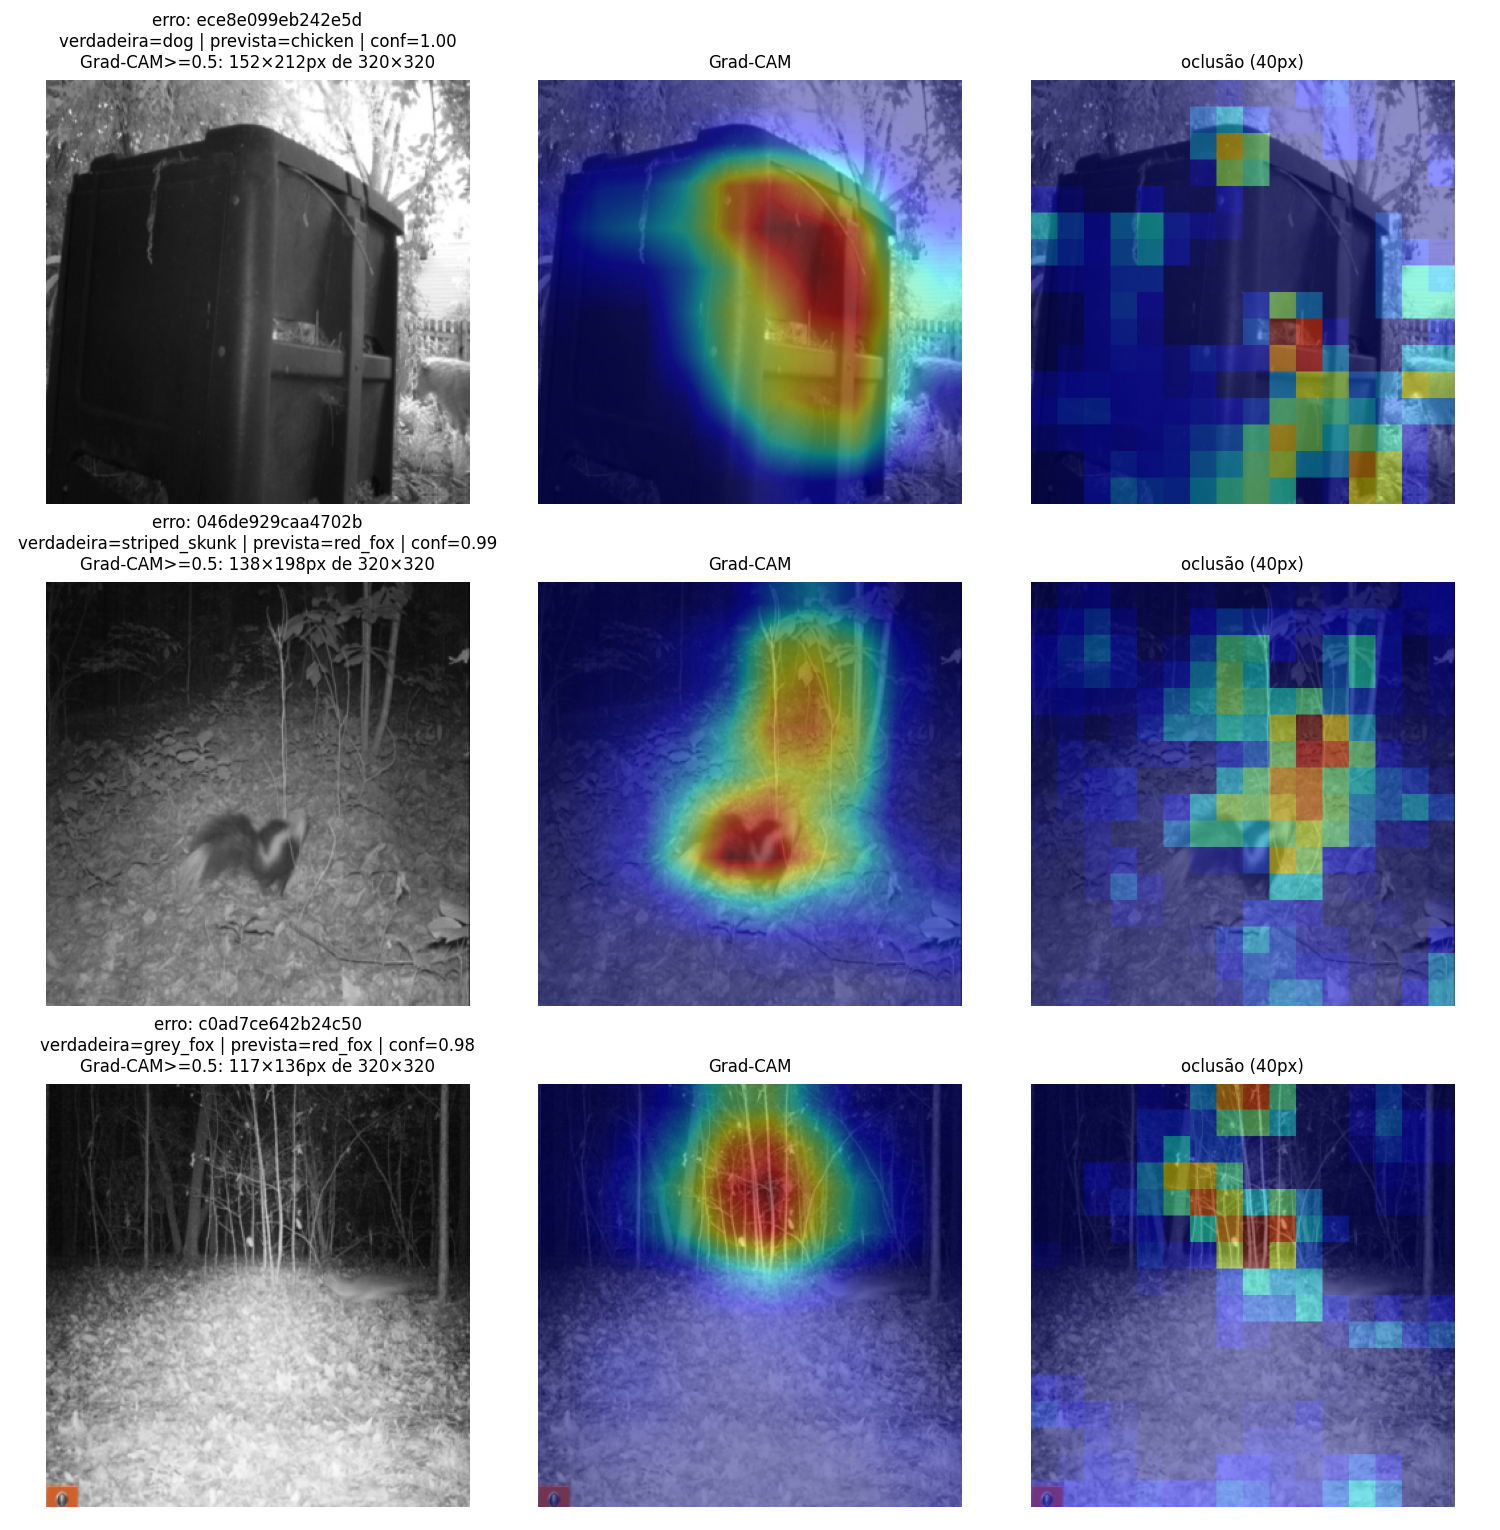

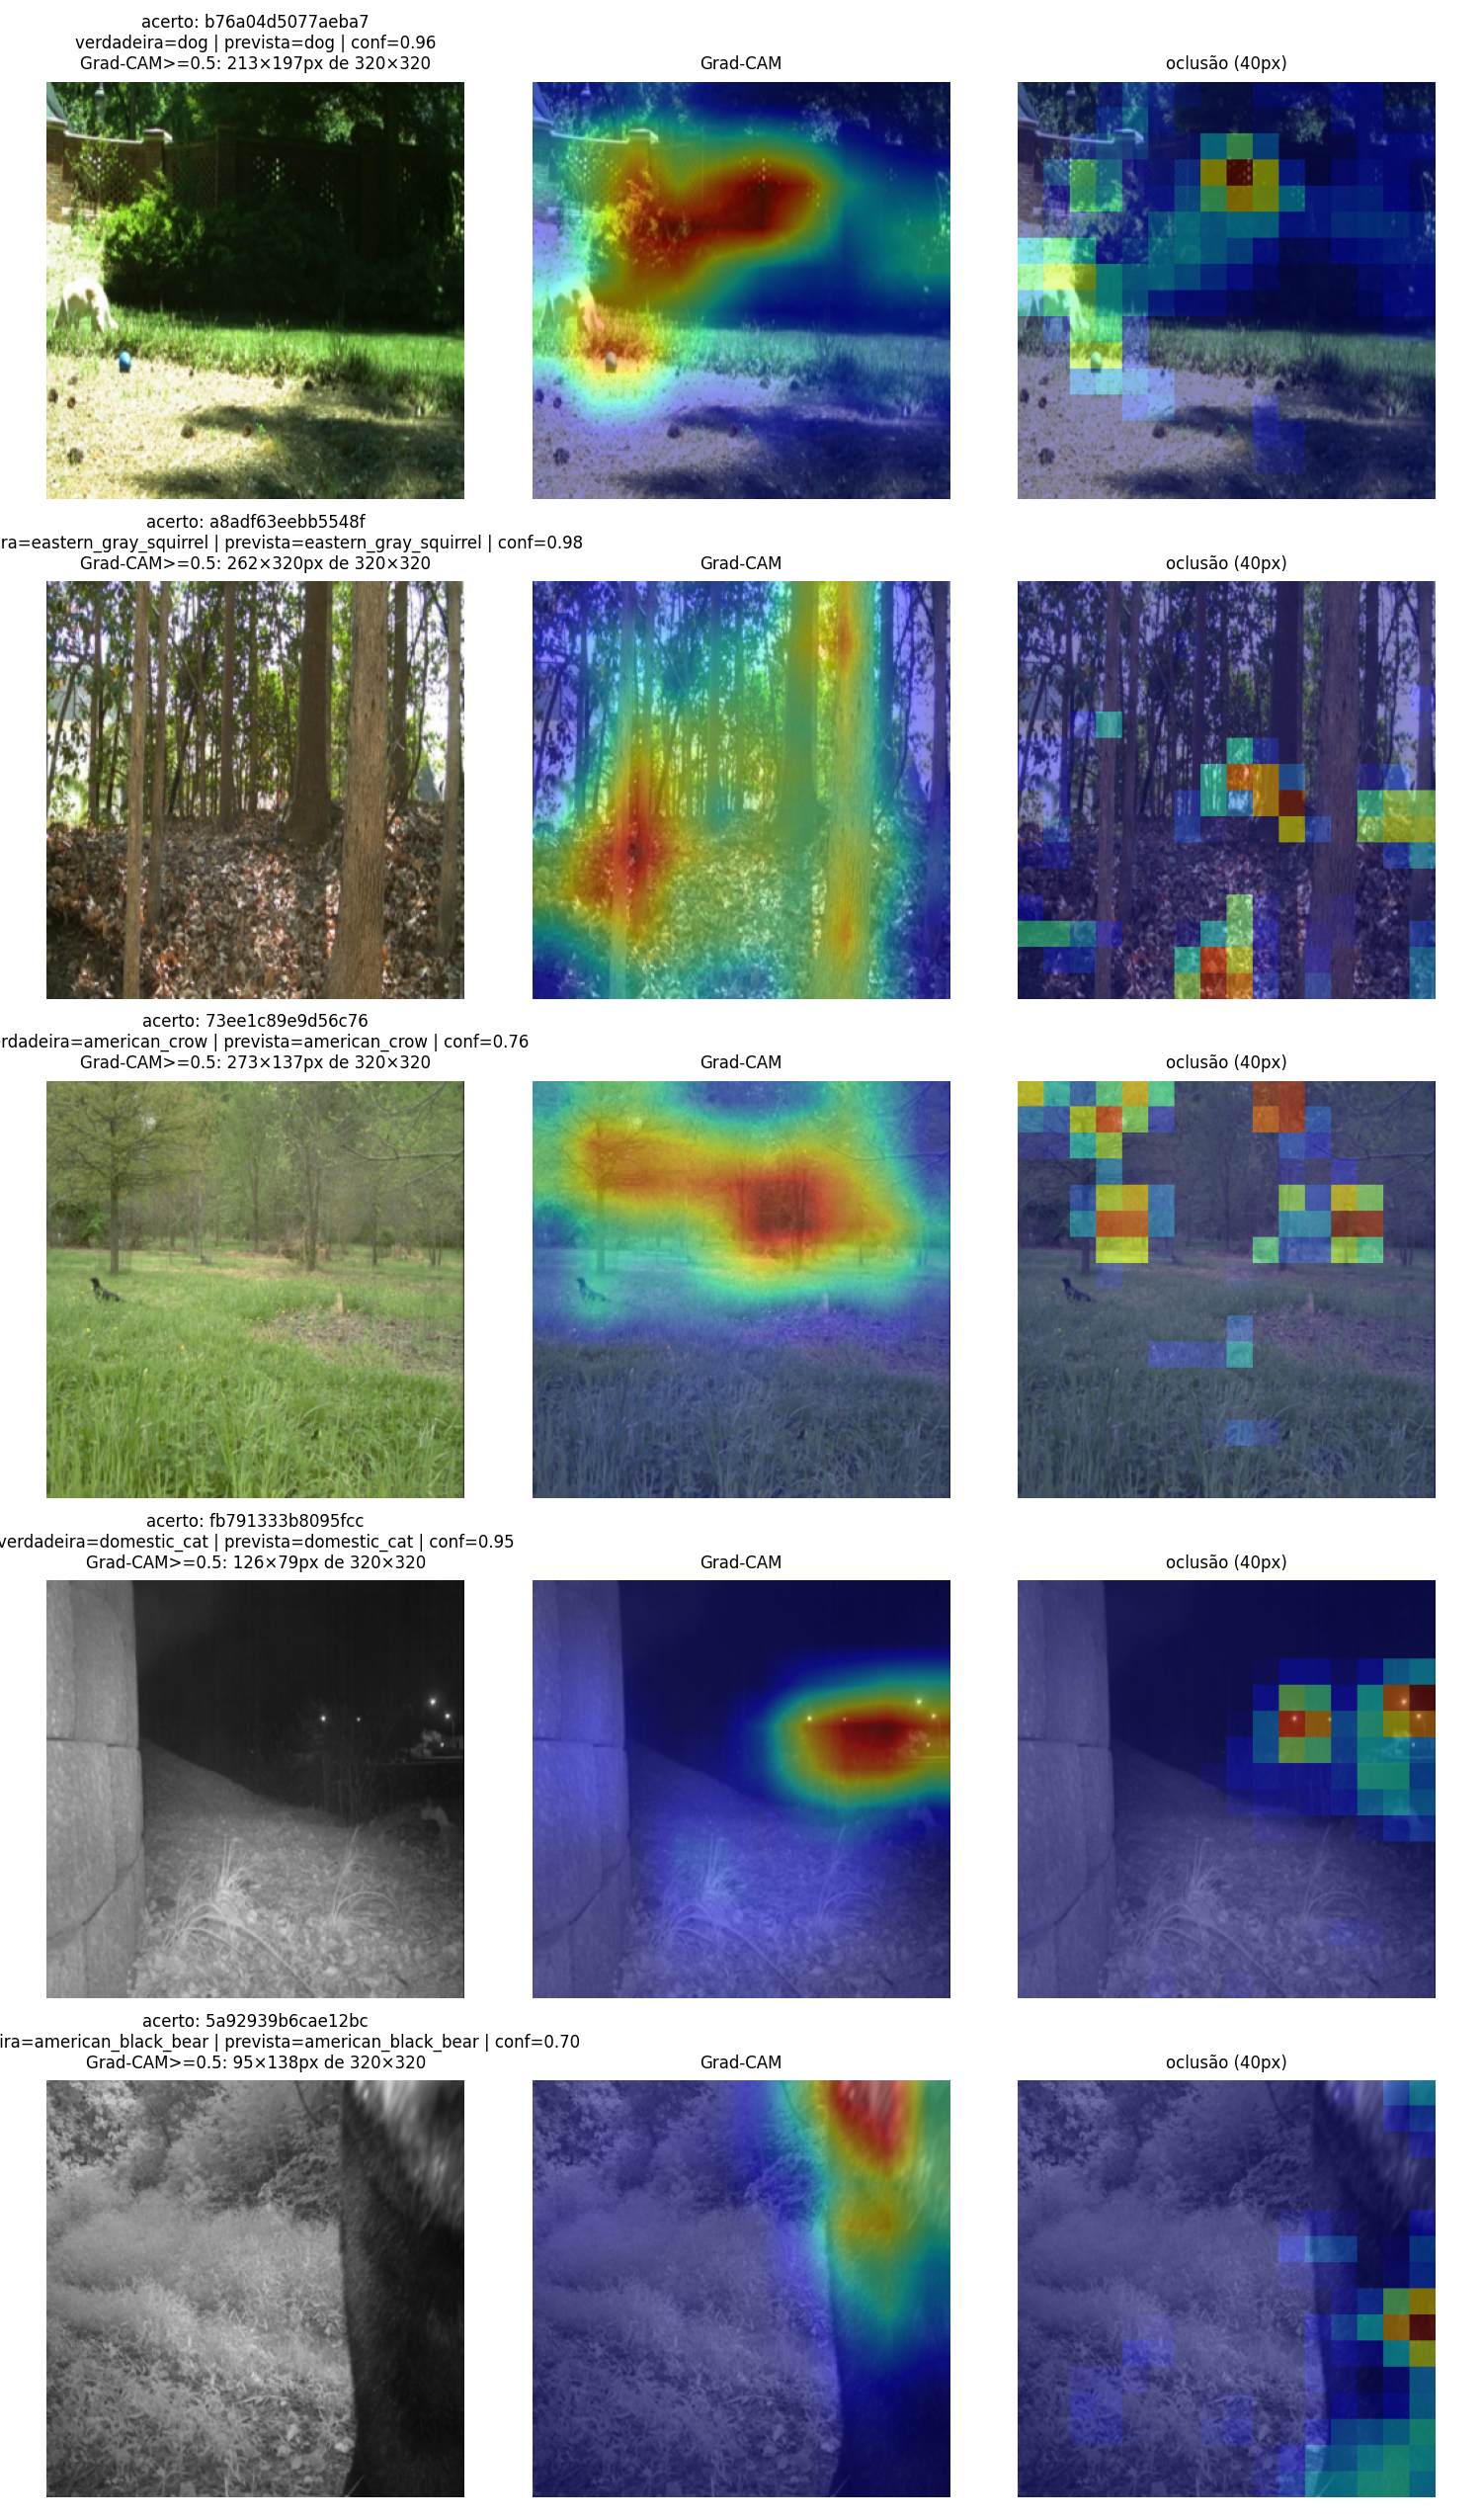

In [10]:
!python -m src.select_final --out {MODELO_OUT} --method fixmatch --data {DADOS} --dest pesos/modelo_final.pt
!python -m src.galeria --data {DADOS} --ckpt pesos/modelo_final.pt --out resultados/parte3
display(Image("resultados/parte3/galeria_erros.png")); display(Image("resultados/parte3/galeria_acertos.png"))

`resultados/parte3/candidatos_erros.csv` lista os 30 erros mais confiantes com atributos contínuos (tamanho, cor, brilho). A coluna `diagnostico` de `galeria_info.csv` recebe o diagnóstico de cada caso (3 erros e 5 acertos), com Grad-CAM e mapa de oclusão. Outros erros podem ser escolhidos com `--ids ID1 ID2 ID3`.

Teste do `predict.py` nas condições do monitor: CPU, sem internet. A simulação bloqueia a rede e oculta a CUDA, e confere o formato do CSV, o número de parâmetros e o tempo.

In [11]:
!python -m tests.check_predict --data {DADOS} --ckpt pesos/modelo_final.pt


===== check_predict =====
[PASS] parâmetros ≤ 12M — 4,034,449
[PASS] class_names do checkpoint == classes.csv
[PASS] predict.py roda (CPU, rede bloqueada)
parametros: 4034449
100 imagens em 16.8s (6.0 img/s, 1 threads) -> /tmp/tmp2rrbfjkp/preds.csv
[PASS] nada foi baixado (TORCH_HOME vazio)
[PASS] imprime nº de parâmetros — [4034449]
[PASS] colunas exatamente image_id,label — ['image_id', 'label']
[PASS] uma linha por imagem — 100/100
[PASS] labels são nomes de classes.csv
[PASS] image_id no mesmo formato dos CSVs do pacote — ex.: predito '008d95903e846282' vs csv '9b18e189485d2914'
[PASS] predict.py == caminho de avaliação do treino — concordância 1.000
[PASS] ~800 imagens < 10 min em CPU — estimativa 2.2 min nesta máquina (168 ms/img, inclui carga do modelo)

check_predict: 11 PASS, 0 WARN, 0 FAIL


Reprodução do número reportado apenas com os artefatos entregues (`predict.py` e `pesos/modelo_final.pt`) sobre uma pasta com as imagens do `test_public`. O F1 de `src.avaliar` deve coincidir com o `test_f1` do run escolhido (diferenças da ordem de 1e-3 são ruído numérico).

In [12]:
sys.path.insert(0, ".")
from src import common as C
sch = C.load_schema(); names, id2idx = C.load_classes(DADOS, sch)
ids, paths, y = C.read_split(DADOS, sch, "test_public", names, id2idx)
os.makedirs("/content/test_public_imgs", exist_ok=True)
for p in paths:
    dst = f"/content/test_public_imgs/{p.name}"
    if not os.path.exists(dst):
        os.symlink(p.resolve(), dst)
GT = str(C.find_file(DADOS, sch["files"]["test_public"]))
if os.path.exists("/content/preds_test.csv"):
    os.remove("/content/preds_test.csv")
!CUDA_VISIBLE_DEVICES="" python predict.py --imagens /content/test_public_imgs --saida /content/preds_test.csv --pesos pesos/modelo_final.pt
!python -m src.avaliar --preds /content/preds_test.csv --gt {GT} --data {DADOS}
sel = json.load(open("pesos/modelo_final.json"))
print("run escolhido:", sel["run"], "| test_f1 do run:", json.load(open(f"{MODELO_OUT}/runs/{sel['run']}/metrics.json"))["test_f1"])

parametros: 4034449
811 imagens em 134.8s (6.0 img/s, 1 threads) -> /content/preds_test.csv
F1 macro 0.4828 | acurácia 0.5302 | n=811
run escolhido: fixmatch_b5_s2 | test_f1 do run: 0.4827582774009079


## 9. Arquivos de saída

In [14]:
dirs = [d for d in ("resultados", "resultados_sem_correcao", "resultados_sem_correcao_tau05", "resultados_3000passos") if os.path.isdir(d)]
!zip -qr /content/resultados_pa3.zip {" ".join(dirs)} -x "*/runs/*/weights.pt" "*/sweeps/*/trials/*"
print("entregáveis:", [p for p in ("pesos/modelo_final.pt", "resultados/curva_orcamento.csv", "predict.py", "README.md", "AI_LOG.md") if os.path.exists(p)])
from google.colab import files
files.download("/content/resultados_pa3.zip")

entregáveis: ['pesos/modelo_final.pt', 'resultados/curva_orcamento.csv', 'predict.py', 'README.md', 'AI_LOG.md']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>